# Chapter 6 — Statistical Machine Learning

**Mata Kuliah:** Deep Learning
**Buku:** Practical Statistics for Data Scientists
**Chapter:** 6 — Statistical Machine Learning

## Tujuan

Pada chapter ini dilakukan reproduksi kode Python dan pembahasan
konsep **statistical machine learning**, yaitu metode supervised
learning yang berbasis data (*data-driven*) dan tidak memaksakan
struktur linear atau struktur menyeluruh lainnya pada data.

Pembahasan meliputi:
1. K-Nearest Neighbors (KNN)
2. Tree Models
3. Bagging dan Random Forest
4. Boosting (XGBoost)

Notebook ini dijalankan di **Google Colab**. Seluruh dataset dibaca
langsung dari repository resmi buku.

## Pendahuluan

Kemajuan terbaru di bidang statistik banyak ditujukan untuk
mengembangkan teknik otomatis yang lebih kuat untuk predictive
modeling, baik regression maupun classification. Seperti metode pada
chapter sebelumnya, metode ini adalah **supervised learning**: dilatih
pada data yang hasilnya sudah diketahui, lalu belajar memprediksi hasil
pada data baru.

Metode-metode ini termasuk dalam **statistical machine learning** dan
berbeda dari metode statistik klasik karena bersifat *data-driven* dan
tidak berupaya memaksakan struktur linear atau struktur menyeluruh
lainnya pada data. Contohnya, K-Nearest Neighbors sangat sederhana:
klasifikasikan suatu record sesuai dengan bagaimana record-record yang
mirip diklasifikasikan.

Teknik yang paling sukses dan paling banyak dipakai didasarkan pada
**ensemble learning** yang diterapkan pada **decision tree**. Ide dasar
ensemble learning adalah memakai banyak model untuk membentuk prediksi,
bukan hanya satu model. Kombinasi ensemble learning dan decision tree
menghasilkan beberapa teknik predictive modeling siap pakai dengan
performa terbaik.

Perkembangan banyak teknik ini ditelusuri ke statistikawan **Leo
Breiman** (UC Berkeley) dan **Jerry Friedman** (Stanford). Pekerjaan
mereka dimulai dari pengembangan tree model pada 1984. Pengembangan
metode ensemble *bagging* dan *boosting* pada 1990-an menjadi fondasi
statistical machine learning.

> **Machine Learning Versus Statistics.** Tidak ada garis tegas yang
> memisahkan keduanya. Machine learning lebih berfokus pada
> pengembangan algoritma yang efisien dan dapat diskalakan ke data
> besar untuk mengoptimalkan model prediktif. Statistik umumnya lebih
> memperhatikan teori probabilistik dan struktur model. Bagging dan
> random forest berkembang di kubu statistik. Boosting berkembang di
> kedua disiplin, tetapi lebih banyak mendapat perhatian di sisi
> machine learning.

## Import Library

In [1]:
# Library tambahan yang belum tersedia secara default di Google Colab
!pip install -q xgboost

In [2]:
import math
from collections import defaultdict
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import preprocessing, metrics
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from xgboost import XGBClassifier

# Alamat folder data pada repository resmi buku
DATA_URL = ('https://raw.githubusercontent.com/gedeck/'
            'practical-statistics-for-data-scientists/master/data/')

%matplotlib inline
sns.set_theme(style="whitegrid")

## Membaca Dataset

Dataset yang digunakan adalah data pinjaman pribadi LendingClub
(*paid off* vs *default*), dalam tiga ukuran:

- `loan200` — 200 pinjaman (untuk contoh KNN kecil)
- `loan3000` — 3.000 pinjaman (untuk tree, random forest, XGBoost)
- `loan_data` — seluruh data pinjaman

In [3]:
loan200 = pd.read_csv(DATA_URL + 'loan200.csv')
loan3000 = pd.read_csv(DATA_URL + 'loan3000.csv')
loan_data = pd.read_csv(DATA_URL + 'loan_data.csv.gz')

for df in (loan200, loan3000, loan_data):
    df['outcome'] = df['outcome'].astype('category')

# Kolom indikator tambahan yang dipakai pada contoh KNN sebagai feature engine.
# Pada sebagian versi data kolom ini sudah ada; jika belum, dibuat dari kolom asal.
if 'delinq_2yrs_zero' not in loan_data.columns:
    loan_data['delinq_2yrs_zero'] = (loan_data['delinq_2yrs'] == 0).astype(int)
if 'pub_rec_zero' not in loan_data.columns:
    loan_data['pub_rec_zero'] = (loan_data['pub_rec'] == 0).astype(int)

print('loan200 :', loan200.shape)
print('loan3000:', loan3000.shape)
print('loan_data:', loan_data.shape)
loan200.head()

loan200 : (201, 3)
loan3000: (3000, 6)
loan_data: (45342, 21)


,outcome,payment_inc_ratio,dti
0,target,9.00000,22.50
1,default,5.46933,21.33
2,paid off,6.90294,8.97
3,paid off,11.14800,1.83
4,default,3.72120,10.81


# 1. K-Nearest Neighbors (KNN)

Ide **K-Nearest Neighbors (KNN)** sangat sederhana. Untuk setiap
record yang akan diklasifikasikan atau diprediksi:

1. Cari **K** record yang memiliki fitur mirip (nilai predictor
   mirip).
2. Untuk **klasifikasi**, cari kelas mayoritas di antara record yang
   mirip tersebut, dan berikan kelas itu pada record baru.
3. Untuk **prediksi** (disebut juga *KNN regression*), cari rata-rata
   di antara record yang mirip tersebut, dan prediksikan rata-rata itu
   untuk record baru.

### Key Terms

- **Neighbor** — record yang memiliki nilai predictor mirip dengan
  record lain.
- **Distance metrics** — ukuran yang meringkas dalam satu angka
  seberapa jauh satu record dari record lain.
- **Standardization (normalization)** — kurangi dengan mean dan bagi
  dengan standard deviation.
- **z-score** — nilai hasil standardisasi.
- **K** — jumlah tetangga yang dipertimbangkan.

KNN adalah salah satu teknik prediksi/klasifikasi paling sederhana:
**tidak ada model yang di-fit** (seperti pada regression). Namun hal ini
tidak berarti KNN prosedur otomatis. Hasil prediksi bergantung pada
bagaimana fitur diskalakan, bagaimana kemiripan diukur, dan seberapa
besar K. Semua predictor juga harus berbentuk numerik.

## Contoh Kecil: Memprediksi Loan Default

Pertimbangkan model sederhana dengan dua predictor:

- `dti` — rasio pembayaran utang (di luar hipotek) terhadap
  pendapatan
- `payment_inc_ratio` — rasio cicilan pinjaman terhadap pendapatan

Kedua rasio dikalikan 100. Dengan 200 pinjaman (`loan200`) yang hasil
biner-nya diketahui dan K = 20, estimasi KNN untuk pinjaman baru
(`newloan`) dapat dihitung. Baris pertama `loan200` dipakai sebagai
pinjaman baru dan dikeluarkan dari data latih.

In [4]:
predictors = ['payment_inc_ratio', 'dti']
outcome = 'outcome'

newloan = loan200.loc[0:0, predictors]
X = loan200.loc[1:, predictors]
y = loan200.loc[1:, outcome]

knn = KNeighborsClassifier(n_neighbors=20)
knn.fit(X, y)

print('Pinjaman baru:')
print(newloan)
print()
print('Prediksi KNN (K=20):', knn.predict(newloan)[0])

Pinjaman baru:
   payment_inc_ratio   dti
0                9.0  22.5

Prediksi KNN (K=20): paid off


Pada buku, 9 pinjaman *default* berada di dalam lingkaran 20 tetangga
terdekat, dibanding 11 pinjaman *paid off*, sehingga hasil prediksinya
*paid off*. Jika hanya 3 tetangga terdekat yang dipertimbangkan,
prediksinya berubah menjadi *default*.

Berikut visualisasi 20 tetangga terdekat dan kemungkinan hasil
prediksi untuk beberapa nilai K.

In [5]:
# Probabilitas (propensity) berdasarkan proporsi kelas di K tetangga terdekat
proba = pd.Series(knn.predict_proba(newloan)[0], index=knn.classes_)
print('Probabilitas KNN (K=20):')
print(proba)

for k in (3, 5, 20):
    knn_k = KNeighborsClassifier(n_neighbors=k).fit(X, y)
    print('K = %2d -> prediksi: %s' % (k, knn_k.predict(newloan)[0]))

Probabilitas KNN (K=20):
default     0.45
paid off    0.55
dtype: float64
K =  3 -> prediksi: default
K =  5 -> prediksi: default
K = 20 -> prediksi: paid off


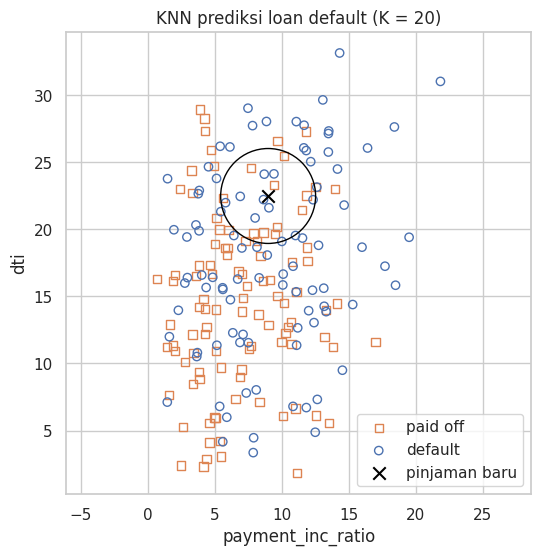

In [6]:
# Visualisasi 20 tetangga terdekat (lingkaran = batas tetangga ke-20)
dist, idx = knn.kneighbors(newloan)
radius = dist[0].max()

fig, ax = plt.subplots(figsize=(6, 6))

for cls, marker, color in [('paid off', 's', 'C1'), ('default', 'o', 'C0')]:
    subset = loan200.loc[1:][loan200.loc[1:, outcome] == cls]
    ax.scatter(subset['payment_inc_ratio'], subset['dti'], marker=marker,
               facecolors='none', edgecolors=color, label=cls)

ax.scatter(*newloan.values[0], marker='x', color='black', s=80, label='pinjaman baru')

circle = plt.Circle(newloan.values[0], radius, color='black', fill=False)
ax.add_patch(circle)

ax.set_xlabel('payment_inc_ratio')
ax.set_ylabel('dti')
ax.set_title('KNN prediksi loan default (K = 20)')
ax.set_aspect('equal', adjustable='datalim')
ax.legend()
plt.show()

> Meskipun keluaran KNN untuk klasifikasi biasanya berupa keputusan
> biner (*default* atau *paid off*), rutin KNN umumnya dapat
> menghasilkan **probabilitas (propensity)** antara 0 dan 1.
> Probabilitas ini didasarkan pada proporsi satu kelas di antara K
> tetangga terdekat. Pada contoh di atas, probabilitas *default*
> adalah 9/20 = 0,45. Dengan probabilitas, kita dapat memakai aturan
> klasifikasi selain suara mayoritas (probabilitas 0,5), yang penting
> pada masalah dengan kelas tidak seimbang. Salah satu pendekatan umum
> adalah menetapkan cutoff pada probabilitas kejadian langka.

## Distance Metrics

Kemiripan (kedekatan) ditentukan dengan **distance metric**, yaitu
fungsi yang mengukur seberapa jauh dua record
$(x_1, x_2, \dots, x_p)$ dan $(u_1, u_2, \dots, u_p)$.

**Euclidean distance** (paling populer):

$$
\sqrt{(x_1-u_1)^2 + (x_2-u_2)^2 + \dots + (x_p-u_p)^2}
$$

**Manhattan distance**:

$$
|x_1-u_1| + |x_2-u_2| + \dots + |x_p-u_p|
$$

Euclidean distance adalah jarak garis lurus (seperti "terbang
burung"). Manhattan distance adalah jarak yang ditempuh satu arah
setiap kali (seperti menyusuri blok kota). Karena itu Manhattan
berguna sebagai pendekatan jika kemiripan didefinisikan sebagai waktu
tempuh antar titik.

> **Other Distance Metrics.** Untuk data numerik, **Mahalanobis
> distance** menarik karena memperhitungkan korelasi antar dua
> variabel: jika dua variabel sangat berkorelasi, Mahalanobis
> memperlakukannya hampir sebagai satu variabel. Euclidean dan
> Manhattan tidak memperhitungkan korelasi. Mahalanobis adalah
> Euclidean distance antar principal components, tetapi memerlukan
> komputasi lebih besar karena dihitung dengan covariance matrix.

In [7]:
# Ilustrasi jarak Euclidean dan Manhattan antara dua record
u = np.array([2.39, 1.00])   # (payment_inc_ratio, dti) contoh
v = np.array([4.57, 5.55])

euclidean = np.sqrt(np.sum((u - v) ** 2))
manhattan = np.sum(np.abs(u - v))

print('Euclidean distance:', round(euclidean, 4))
print('Manhattan distance:', round(manhattan, 4))

Euclidean distance: 5.0453
Manhattan distance: 6.73


Pada pengukuran jarak, variabel yang diukur dengan skala yang relatif
besar akan mendominasi ukuran jarak. Pada data pinjaman, jarak hampir
sepenuhnya ditentukan oleh `income` dan `loan amount` yang bernilai
puluhan atau ratusan ribu, sedangkan variabel rasio nyaris tidak
berpengaruh. Masalah ini diatasi dengan **standardisasi** (dibahas
berikut).

## One Hot Encoder

Data pinjaman LendingClub memuat beberapa variabel faktor (string).
Sebagian besar model statistik dan machine learning mengharuskan
variabel jenis ini diubah menjadi serangkaian **dummy variable
biner** yang memuat informasi yang sama.

Misalnya, satu variabel status kepemilikan rumah ("memiliki dengan
hipotek", "memiliki tanpa hipotek", "menyewa", "lainnya") menjadi
empat variabel biner. Istilah *one hot encoding* berasal dari
terminologi sirkuit digital, di mana hanya satu bit yang boleh
positif ("hot").

In [8]:
# Contoh Table 6-1 -> Table 6-2: status kepemilikan rumah diubah menjadi dummy
home = pd.DataFrame({'home_ownership': ['MORTGAGE', 'MORTGAGE', 'MORTGAGE',
                                        'MORTGAGE', 'RENT', 'RENT']})
pd.get_dummies(home, dtype=int)

,home_ownership_MORTGAGE,home_ownership_RENT
0,1,0
1,1,0
2,1,0
3,1,0
4,0,1
5,0,1


> Pada linear dan logistic regression, one hot encoding menimbulkan
> masalah **multicollinearity**, sehingga satu dummy dibuang (nilainya
> dapat disimpulkan dari yang lain). Hal ini tidak menjadi masalah pada
> KNN dan metode lain yang dibahas dalam chapter ini.

## Standardization (Normalization, z-Scores)

Dalam pengukuran, sering kali yang menarik bukan "berapa banyak",
tetapi "seberapa berbeda dari rata-rata". **Standardisasi**
(normalisasi) menyamakan skala semua variabel dengan mengurangi mean
dan membagi dengan standard deviation, sehingga suatu variabel tidak
terlalu memengaruhi model hanya karena skala pengukuran aslinya:

$$
z = \frac{x - \bar{x}}{s}
$$

Hasil transformasi ini disebut **z-score**. Pengukuran kemudian
dinyatakan dalam "berapa standard deviation dari rata-rata".

> Normalisasi pada konteks statistik ini tidak sama dengan
> normalisasi database (menghapus data redundan).

Untuk KNN dan beberapa prosedur lain (misalnya PCA dan clustering),
standardisasi data sebelum prosedur diterapkan sangat penting.
Sebagai ilustrasi, KNN diterapkan pada data pinjaman memakai `dti` dan
`payment_inc_ratio` ditambah dua variabel lain:

- `revol_bal` — total kredit revolving yang tersedia bagi pemohon
  (dalam dolar)
- `revol_util` — persentase kredit yang digunakan

Magnitudo `revol_bal` (dalam dolar) jauh lebih besar dibanding
variabel lain. Berikut lima tetangga terdekat **tanpa standardisasi**:

In [9]:
predictors = ['payment_inc_ratio', 'dti', 'revol_bal', 'revol_util']
outcome = 'outcome'

newloan = loan_data.loc[0:0, predictors]
X = loan_data.loc[1:, predictors]
y = loan_data.loc[1:, outcome]

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X, y)

print('Pinjaman baru:')
print(newloan)
print()
print('Lima tetangga terdekat (tanpa standardisasi):')
nbrs = knn.kneighbors(newloan)
X.iloc[nbrs[1][0], :]

Pinjaman baru:
   payment_inc_ratio  dti  revol_bal  revol_util
0             2.3932  1.0       1687         9.4

Lima tetangga terdekat (tanpa standardisasi):


,payment_inc_ratio,dti,revol_bal,revol_util
35536,1.47212,1.46,1686,10.0
33651,3.38178,6.37,1688,8.4
25863,2.36303,1.39,1691,3.5
42953,1.28160,7.14,1684,3.9
43599,4.12244,8.98,1684,7.2


Nilai `revol_bal` pada tetangga-tetangga ini sangat dekat dengan nilai
pada record baru, tetapi variabel predictor lainnya "tersebar ke mana-mana"
dan pada dasarnya tidak berperan dalam menentukan tetangga.

Sekarang bandingkan dengan KNN pada data yang sudah **distandardisasi**
memakai `StandardScaler`. Scaler dilatih dengan predictor, kemudian
dipakai untuk mentransformasi data sebelum model KNN dilatih.

In [10]:
newloan = loan_data.loc[0:0, predictors]
X = loan_data.loc[1:, predictors]
y = loan_data.loc[1:, outcome]

scaler = preprocessing.StandardScaler()
scaler.fit(X * 1.0)

X_std = scaler.transform(X * 1.0)
newloan_std = scaler.transform(newloan * 1.0)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_std, y)

print('Lima tetangga terdekat (dengan standardisasi):')
nbrs = knn.kneighbors(newloan_std)
X.iloc[nbrs[1][0], :]

Lima tetangga terdekat (dengan standardisasi):


,payment_inc_ratio,dti,revol_bal,revol_util
2080,2.61091,1.03,1218,9.7
1438,2.34343,0.51,278,9.9
30215,2.71200,1.34,1075,8.5
28542,2.39760,0.74,2917,7.4
44737,2.34309,1.37,488,7.2


Lima tetangga terdekat kini jauh lebih mirip pada semua variabel,
sehingga hasilnya lebih masuk akal. Hasil ditampilkan pada skala
asli, tetapi KNN diterapkan pada data yang telah diskalakan.

> Z-score hanyalah salah satu cara menskalakan ulang variabel. Sebagai
> ganti mean, bisa dipakai estimasi lokasi yang lebih robust seperti
> median. Demikian juga sebagai ganti standard deviation dapat dipakai
> estimasi skala lain seperti interquartile range. Kadang variabel
> "dipadatkan" ke rentang 0-1. Perlu disadari bahwa menskalakan
> setiap variabel ke varians satuan agak arbitrer, karena menyiratkan
> bahwa tiap variabel dianggap sama penting. Jika ada pengetahuan
> subjektif bahwa sebagian variabel lebih penting, variabel tersebut
> dapat diberi skala lebih besar. Normalisasi tidak mengubah bentuk
> distribusi data.

## Choosing K

Pemilihan **K** sangat penting bagi performa KNN. Pilihan paling
sederhana adalah K = 1 (*1-nearest neighbor classifier*): prediksi
berdasarkan record paling mirip pada training set. K = 1 jarang
menjadi pilihan terbaik; performa yang lebih baik hampir selalu
diperoleh dengan K > 1.

- Jika K **terlalu kecil**, kita mungkin **overfitting**: ikut
  memasukkan *noise* pada data.
- Jika K **terlalu besar**, data menjadi **terlalu mulus
  (oversmoothing)** dan KNN kehilangan kemampuan menangkap struktur
  lokal, yang merupakan salah satu keunggulan utamanya.

K yang paling menyeimbangkan keduanya umumnya ditentukan dengan metrik
akurasi, khususnya akurasi pada data holdout atau validasi. Tidak ada
aturan umum untuk K terbaik; semuanya bergantung pada sifat data.
Untuk data yang sangat terstruktur dan sedikit noise (*signal-to-noise
ratio* tinggi, misalnya pengenalan tulisan tangan dan suara), K kecil
bekerja paling baik. Untuk data berisik dengan struktur sedikit (SNR
rendah) seperti data pinjaman, K yang lebih besar lebih sesuai.
Biasanya K berada di rentang 1 sampai 20, dan sering dipilih bilangan
ganjil untuk menghindari hasil seri.

> **Bias-Variance Trade-off.** Ketegangan antara oversmoothing dan
> overfitting adalah contoh *bias-variance trade-off*. **Variance**
> adalah error pemodelan akibat pemilihan data latih (jika data latih
> berbeda, modelnya berbeda). **Bias** adalah error pemodelan karena
> skenario dunia nyata tidak teridentifikasi dengan benar; error ini
> tidak hilang hanya dengan menambah data latih. Ketika model fleksibel
> overfit, variance meningkat. Pendekatan umum untuk menangani
> trade-off ini adalah **cross-validation**.

Berikut eksperimen sederhana memilih K berdasarkan akurasi pada data
validasi (data distandardisasi).

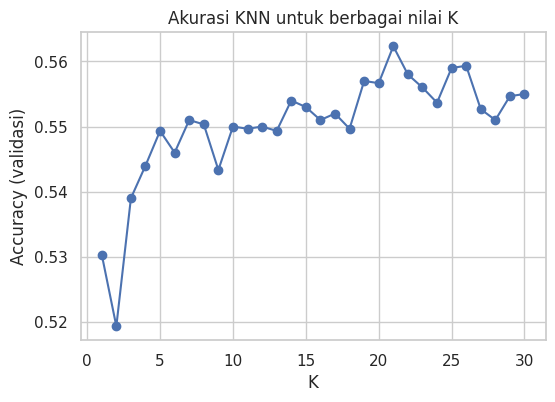

K terbaik pada data validasi: 21


In [11]:
# Pilih K berdasarkan akurasi pada data validasi (holdout)
sample = loan_data.sample(n=10000, random_state=1) if len(loan_data) > 10000 else loan_data
X_all = sample[predictors] * 1.0
y_all = sample[outcome]

train_X, valid_X, train_y, valid_y = train_test_split(
    X_all, y_all, test_size=0.3, random_state=1)

sc = preprocessing.StandardScaler().fit(train_X)
train_Xs, valid_Xs = sc.transform(train_X), sc.transform(valid_X)

results = []
for k in range(1, 31):
    knn_k = KNeighborsClassifier(n_neighbors=k).fit(train_Xs, train_y)
    results.append({'k': k, 'accuracy': metrics.accuracy_score(valid_y, knn_k.predict(valid_Xs))})
results = pd.DataFrame(results)

ax = results.plot(x='k', y='accuracy', marker='o', figsize=(6, 4), legend=False)
ax.set_xlabel('K')
ax.set_ylabel('Accuracy (validasi)')
ax.set_title('Akurasi KNN untuk berbagai nilai K')
plt.show()

print('K terbaik pada data validasi:', int(results.loc[results.accuracy.idxmax(), 'k']))

## KNN as a Feature Engine

KNN populer karena kesederhanaan dan sifatnya yang intuitif. Dari sisi
performa, KNN sendiri biasanya tidak kompetitif dibanding teknik
klasifikasi yang lebih canggih. Namun dalam praktik pemodelan, KNN
dapat dipakai untuk menambahkan "pengetahuan lokal" dalam proses
bertahap bersama teknik klasifikasi lain:

1. KNN dijalankan pada data, dan untuk setiap record diturunkan
   klasifikasi (atau kuasi-probabilitas kelas).
2. Hasil itu ditambahkan sebagai **fitur baru** pada record, lalu
   metode klasifikasi lain dijalankan pada data. Variabel predictor asli
   dengan demikian dipakai dua kali.

Sekilas, hal ini tampak menimbulkan multicollinearity, tetapi bukan
masalah, karena informasi yang dimasukkan ke model tahap kedua bersifat
sangat **lokal**, hanya diturunkan dari beberapa record di dekatnya,
sehingga merupakan informasi tambahan, bukan redundan.

Penggunaan bertahap ini dapat dipandang sebagai bentuk **ensemble
learning**, dan juga **feature engineering** yang bertujuan menurunkan
fitur dengan daya prediksi.

Contoh: pada data harga rumah King County, agen properti mematok harga
berdasarkan rumah serupa yang baru terjual ("comps"). Itu pada dasarnya
versi manual dari KNN. Kita dapat membuat fitur baru yang meniru agen
properti dengan menerapkan KNN pada penjualan terbaru. Karena yang
diprediksi nilai numerik, rata-rata K tetangga dipakai sebagai ganti
suara mayoritas (*KNN regression*).

Pada data pinjaman, dibuat fitur yang mewakili **kelayakan kredit**
(*creditworthiness*) peminjam berdasarkan riwayat kredit.

In [12]:
predictors = ['dti', 'revol_bal', 'revol_util', 'open_acc',
              'delinq_2yrs_zero', 'pub_rec_zero']
outcome = 'outcome'

X = loan_data[predictors]
y = loan_data[outcome]

knn = KNeighborsClassifier(n_neighbors=20)
knn.fit(X, y)

# Probabilitas default diambil dari kolom kelas 'default' (lihat knn.classes_)
default_col = list(knn.classes_).index('default')
loan_data['borrower_score_knn'] = knn.predict_proba(X)[:, default_col]
loan_data['borrower_score_knn'].describe()

,borrower_score_knn
count,45342.000000
mean,0.501098
std,0.128736
min,0.000000
25%,0.400000
50%,0.500000
75%,0.600000
max,0.950000


Hasilnya adalah fitur yang memprediksi kemungkinan peminjam gagal bayar
berdasarkan riwayat kreditnya. Fitur ini dinamai `borrower_score_knn`
agar tidak menimpa kolom `borrower_score` yang sudah ada pada dataset.
Kolom probabilitas yang diambil adalah kolom kelas *default*
(`knn.classes_` diurutkan alfabet).

### Key Ideas — K-Nearest Neighbors

- KNN mengklasifikasikan record dengan memberinya kelas dari record
  yang mirip.
- Kemiripan (jarak) ditentukan oleh Euclidean distance atau metrik
  terkait.
- Jumlah tetangga terdekat K ditentukan dari performa algoritma pada
  data latih dengan berbagai nilai K.
- Biasanya variabel predictor distandardisasi agar variabel berskala
  besar tidak mendominasi metrik jarak.
- KNN sering dipakai sebagai tahap pertama predictive modeling, dengan
  nilai prediksinya ditambahkan kembali ke data sebagai predictor untuk
  pemodelan tahap kedua (non-KNN).

# 2. Tree Models

**Tree models**, disebut juga *Classification and Regression Trees
(CART)*, *decision trees*, atau sekadar *trees*, adalah metode
klasifikasi (dan regression) yang efektif dan populer, awalnya
dikembangkan oleh Leo Breiman dan kawan-kawan pada 1984. Tree model,
beserta turunannya yang lebih kuat (random forest dan boosted trees),
membentuk dasar perangkat predictive modeling yang paling banyak dan
paling kuat dipakai di data science untuk regression dan klasifikasi.

### Key Terms

- **Recursive partitioning** — membagi dan membagi lagi data
  berulang-ulang dengan tujuan membuat hasil pada tiap subdivisi akhir
  sehomogen mungkin.
- **Split value** — nilai predictor yang membagi record menjadi yang
  nilainya kurang dari dan yang lebih dari nilai itu.
- **Node** — representasi grafis atau aturan dari sebuah split value.
- **Leaf** — ujung dari satu set aturan if-then, yaitu cabang tree;
  aturan yang mengarah ke leaf memberi salah satu aturan klasifikasi.
- **Loss** — jumlah salah klasifikasi pada tahap proses splitting;
  semakin banyak loss, semakin tidak murni.
- **Impurity** — sejauh mana campuran kelas ditemukan pada subpartisi
  data (semakin tercampur, semakin tidak murni). Antonim:
  homogeneity, purity.
- **Pruning** — memangkas cabang tree yang telah tumbuh penuh secara
  bertahap untuk mengurangi overfitting.

Tree model adalah serangkaian aturan **if-then-else** yang mudah
dipahami dan diimplementasikan. Berbeda dengan linear dan logistic
regression, tree mampu menemukan pola tersembunyi yang berkaitan
dengan interaksi kompleks pada data. Namun berbeda dengan KNN atau
naive Bayes, tree model sederhana dapat dinyatakan sebagai hubungan
predictor yang mudah diinterpretasi.

> **Decision Trees in Operations Research.** Istilah *decision trees*
> memiliki arti lain (dan lebih lama) pada ilmu keputusan dan riset
> operasi: proses analisis keputusan manusia dengan titik keputusan,
> kemungkinan hasil, dan perkiraan probabilitasnya digambarkan dalam
> diagram bercabang, lalu dipilih jalur dengan expected value
> maksimum.

## Contoh Sederhana

Tree model dicocokkan pada sampel 3.000 record data pinjaman
(`loan3000`) dengan dua variabel: `payment_inc_ratio` dan
`borrower_score`. Di Python digunakan `DecisionTreeClassifier`.

In [13]:
predictors = ['borrower_score', 'payment_inc_ratio']
outcome = 'outcome'

X = loan3000[predictors]
y = loan3000[outcome]

loan_tree = DecisionTreeClassifier(random_state=1, criterion='entropy',
                                   min_impurity_decrease=0.003)
loan_tree.fit(X, y)

print('Kedalaman tree     :', loan_tree.get_depth())
print('Jumlah leaf (daun) :', loan_tree.get_n_leaves())

Kedalaman tree     : 3
Jumlah leaf (daun) : 6


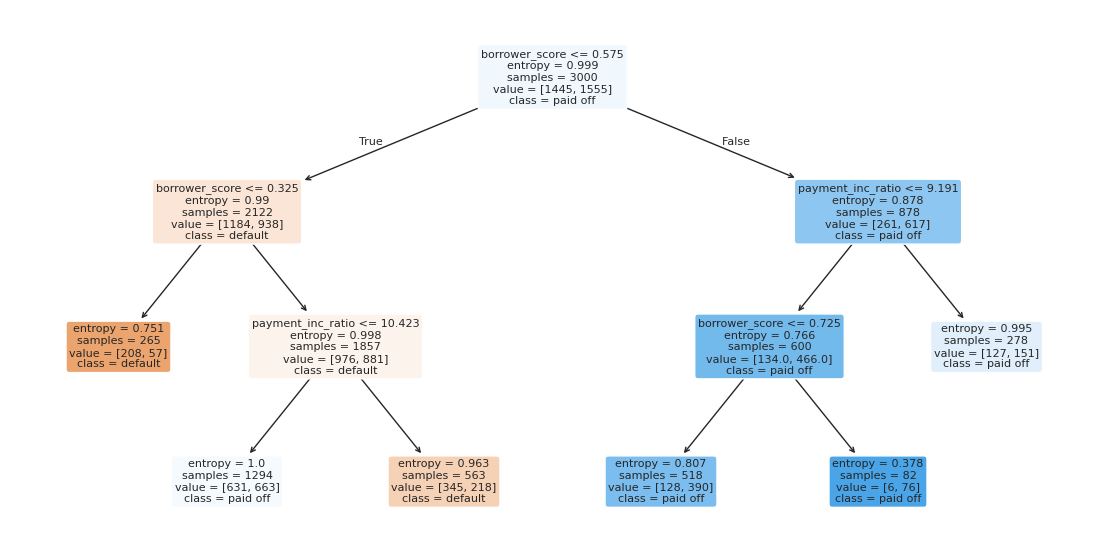

In [14]:
# Visualisasi tree (setara dengan plotDecisionTree dari package dmba pada buku)
fig, ax = plt.subplots(figsize=(14, 7))
plot_tree(loan_tree, feature_names=predictors,
          class_names=list(loan_tree.classes_),
          filled=True, rounded=True, fontsize=8, ax=ax)
plt.show()

Aturan klasifikasi ditentukan dengan menelusuri tree hierarkis, mulai
dari **root**, bergerak ke kiri jika kondisi pada node benar dan ke
kanan jika tidak, sampai mencapai **leaf**. Tree biasanya digambar
terbalik: root di atas dan leaf di bawah.

Karena perbedaan implementasi, hasil dari R dan Python tidak persis
sama; hal ini wajar.

Representasi teks dari tree juga mudah dibuat (setara dengan
`textDecisionTree` dari dmba pada buku):

In [15]:
print(export_text(loan_tree, feature_names=predictors))

|--- borrower_score <= 0.58
|   |--- borrower_score <= 0.33
|   |   |--- class: default
|   |--- borrower_score >  0.33
|   |   |--- payment_inc_ratio <= 10.42
|   |   |   |--- class: paid off
|   |   |--- payment_inc_ratio >  10.42
|   |   |   |--- class: default
|--- borrower_score >  0.58
|   |--- payment_inc_ratio <= 9.19
|   |   |--- borrower_score <= 0.72
|   |   |   |--- class: paid off
|   |   |--- borrower_score >  0.72
|   |   |   |--- class: paid off
|   |--- payment_inc_ratio >  9.19
|   |   |--- class: paid off



Kedalaman indentasi menunjukkan kedalaman tree. Setiap node memuat
klasifikasi sementara yang ditentukan oleh hasil yang dominan pada
partisi tersebut. Nilai pada leaf menunjukkan kelas hasil prediksi.

## The Recursive Partitioning Algorithm

Algoritma untuk membangun decision tree, yaitu **recursive
partitioning**, sederhana dan intuitif. Data dipartisi berulang kali
memakai nilai predictor yang paling baik memisahkan data menjadi
partisi yang relatif homogen.

Misalkan ada variabel respons Y dan P variabel predictor $X_j$ untuk
$j = 1, \dots, P$. Untuk partisi A dari record, recursive partitioning
mencari cara terbaik membagi A menjadi dua subpartisi:

1. Untuk setiap variabel predictor $X_j$:
   1. Untuk setiap nilai $s_j$ dari $X_j$:
      - Pisahkan record di A dengan nilai $X_j < s_j$ sebagai satu
        partisi, dan sisanya ($X_j \ge s_j$) sebagai partisi lain.
      - Ukur homogenitas kelas pada tiap subpartisi A.
   2. Pilih nilai $s_j$ yang menghasilkan homogenitas kelas
      dalam-partisi maksimum.
2. Pilih variabel $X_j$ dan nilai split $s_j$ yang menghasilkan
   homogenitas kelas dalam-partisi maksimum.

Bagian **rekursif**-nya:

1. Inisialisasi A dengan seluruh data.
2. Terapkan algoritma partisi untuk membagi A menjadi dua subpartisi,
   $A_1$ dan $A_2$.
3. Ulangi langkah 2 pada subpartisi $A_1$ dan $A_2$.
4. Algoritma berhenti ketika tidak ada lagi partisi yang cukup
   memperbaiki homogenitas.

Hasil akhirnya adalah partisi data dengan setiap partisi memprediksi
hasil 0 atau 1 berdasarkan suara mayoritas respons di partisi itu.

> Selain prediksi biner 0/1, tree model dapat menghasilkan estimasi
> probabilitas berdasarkan jumlah 0 dan 1 di partisi:
>
> $\text{Prob}(Y=1) = \dfrac{\text{jumlah 1 pada partisi}}{\text{ukuran partisi}}$
>
> Estimasi ini dapat dikonversi menjadi keputusan biner, misalnya 1 jika
> Prob(Y = 1) > 0,5.

Visualisasi partisi ruang predictor oleh tree di atas:

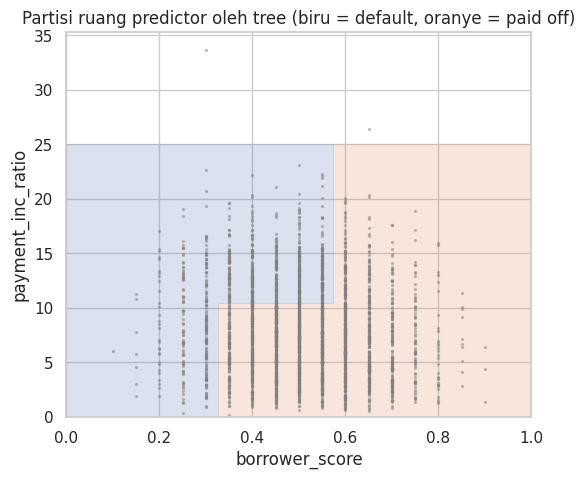

In [16]:
# Wilayah keputusan (partisi) hasil tree pada ruang predictor
xx, yy = np.meshgrid(np.linspace(0, 1, 300), np.linspace(0, 25, 300))
grid = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=predictors)
zz = loan_tree.predict(grid)
zz_num = (zz == 'default').reshape(xx.shape).astype(int)

fig, ax = plt.subplots(figsize=(6, 5))
ax.contourf(xx, yy, zz_num, alpha=0.2, levels=[-0.5, 0.5, 1.5], colors=['C1', 'C0'])
ax.scatter(loan3000['borrower_score'], loan3000['payment_inc_ratio'],
           s=2, color='grey', alpha=0.4)
ax.set_xlabel('borrower_score')
ax.set_ylabel('payment_inc_ratio')
ax.set_title('Partisi ruang predictor oleh tree (biru = default, oranye = paid off)')
plt.show()

## Measuring Homogeneity or Impurity

Tree model secara rekursif membuat partisi (kumpulan record) A yang
memprediksi hasil Y = 0 atau Y = 1. Dari algoritma di atas, kita
membutuhkan cara mengukur **homogenitas** (kemurnian kelas, *class
purity*) di dalam suatu partisi, atau sebaliknya mengukur
**impurity**. Akurasi prediksi adalah proporsi p record yang salah
diklasifikasikan di dalam partisi, berkisar dari 0 (sempurna) sampai
0,5 (tebakan acak murni).

Ternyata akurasi bukan ukuran impurity yang baik. Dua ukuran impurity
yang umum adalah **Gini impurity** dan **entropy of information**. Pada
kasus biner:

$$
\text{Gini: } I(A) = p(1-p)
$$

$$
\text{Entropy: } I(A) = -p\log_2(p) - (1-p)\log_2(1-p)
$$

Gini impurity (diskalakan ulang) dan entropy mirip, dengan entropy
memberi skor impurity lebih tinggi untuk tingkat akurasi sedang dan
tinggi.

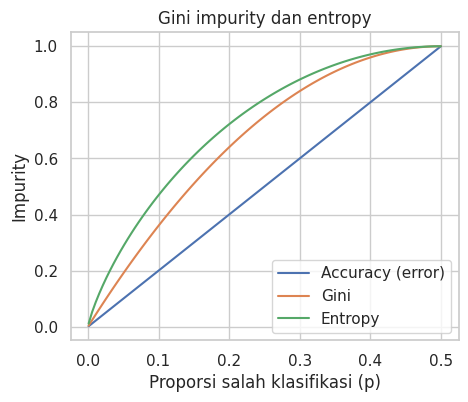

In [17]:
def entropy(p):
    p = np.asarray(p, dtype=float)
    return -p * np.log2(p) - (1 - p) * np.log2(1 - p)

def gini(p):
    return p * (1 - p)

p = np.linspace(0.001, 0.5, 100)
impure = pd.DataFrame({
    'p': p,
    'Accuracy (error)': 2 * p,
    'Gini': gini(p) / gini(0.5),     # diskalakan ulang agar maksimum = 1
    'Entropy': entropy(p),
})

fig, ax = plt.subplots(figsize=(5, 4))
impure.plot(x='p', ax=ax)
ax.set_xlabel('Proporsi salah klasifikasi (p)')
ax.set_ylabel('Impurity')
ax.set_title('Gini impurity dan entropy')
plt.show()

> **Gini Coefficient.** Gini impurity tidak sama dengan *Gini
> coefficient*. Keduanya mewakili konsep serupa, tetapi Gini
> coefficient terbatas pada klasifikasi biner dan terkait dengan
> metrik AUC.

Metrik impurity dipakai pada algoritma splitting. Untuk setiap
partisi data yang diusulkan, impurity diukur untuk tiap partisi hasil
split. Kemudian dihitung **rata-rata berbobot**, dan partisi (pada tiap
tahap) yang menghasilkan rata-rata berbobot terendah dipilih.

## Stopping the Tree from Growing

Seiring tree tumbuh semakin besar, aturan splitting menjadi semakin
rinci, dan tree beralih dari mengidentifikasi aturan "besar" yang
mencerminkan hubungan nyata dan andal pada data menjadi aturan
"kecil" yang hanya mencerminkan **noise**. Tree yang tumbuh penuh
menghasilkan leaf yang murni sepenuhnya dan akurasi 100% pada data
latihnya, tetapi akurasi ini semu: kita telah **overfit**, mencocokkan
noise pada data latih, bukan sinyal yang ingin dikenali pada data
baru.

Kita butuh cara menentukan kapan berhenti menumbuhkan tree pada tahap
yang akan menggeneralisasi ke data baru. Beberapa cara di Python:

- Hindari splitting jika subpartisi atau leaf terminal terlalu kecil.
  Di `DecisionTreeClassifier`, hal ini dikendalikan dengan
  `min_samples_split` (default 2) dan `min_samples_leaf` (default 1).
- Jangan split partisi jika partisi baru tidak "signifikan"
  menurunkan impurity. `DecisionTreeClassifier` memiliki parameter
  `min_impurity_decrease` yang membatasi splitting berdasarkan
  penurunan impurity berbobot. Nilai kecil menghasilkan tree lebih
  kompleks.

Metode ini melibatkan aturan arbitrer dan berguna untuk kerja
eksploratif, tetapi kita tidak mudah menentukan nilai optimum (yaitu
yang memaksimalkan akurasi prediksi pada data baru). Perlu
dikombinasikan **cross-validation** dengan perubahan sistematis pada
parameter model atau modifikasi tree melalui pruning.

**Controlling tree complexity in R.** Di R, parameter kompleksitas
`cp` dipakai untuk memperkirakan ukuran tree terbaik. Jika `cp` terlalu
kecil tree overfit, jika terlalu besar tree terlalu kecil dan daya
prediksinya rendah. Nilai `cp` terbaik biasanya diperkirakan dengan
cross-validation.

**Controlling tree complexity in Python.** Implementasi decision tree
scikit-learn tidak memiliki parameter kompleksitas `cp` bergaya R
maupun pruning bergaya R. Solusinya adalah **grid search** atas
kombinasi nilai parameter. Misalnya `max_depth` dari 5 sampai 30 dan
`min_samples_split` antara 20 dan 100. `GridSearchCV` adalah cara
praktis menggabungkan pencarian menyeluruh pada semua kombinasi dengan
cross-validation. Set parameter optimal dipilih dari performa model
hasil cross-validation.

In [18]:
param_grid = {
    'max_depth': [5, 10, 20, 30],
    'min_samples_split': [20, 40, 60, 80, 100],
    'min_impurity_decrease': [0, 0.0005, 0.001, 0.005, 0.01],
}

grid_search = GridSearchCV(DecisionTreeClassifier(random_state=1),
                           param_grid, cv=5, n_jobs=-1)
grid_search.fit(X, y)

print('Skor terbaik (cross-validation):', round(grid_search.best_score_, 4))
print('Parameter terbaik:', grid_search.best_params_)

Skor terbaik (cross-validation): 0.6123
Parameter terbaik: {'max_depth': 5, 'min_impurity_decrease': 0.0005, 'min_samples_split': 20}


## Predicting a Continuous Value

Memprediksi nilai kontinu (disebut juga **regression**) dengan tree
mengikuti logika dan prosedur yang sama, kecuali impurity diukur
dengan **deviasi kuadrat dari mean** (squared errors) pada setiap
subpartisi, dan performa prediksi dinilai dengan **RMSE** (akar dari
mean squared error) pada setiap partisi. scikit-learn menyediakan
`DecisionTreeRegressor` untuk melatih model regression tree.

## How Trees Are Used

Salah satu hambatan besar bagi predictive modeler di organisasi adalah
anggapan bahwa metode yang dipakai bersifat "kotak hitam", yang
memunculkan penolakan dari bagian lain organisasi. Dalam hal ini tree
model memiliki dua aspek menarik:

- Tree model menyediakan **alat visual** untuk mengeksplorasi data,
  memahami variabel mana yang penting dan bagaimana hubungannya. Tree
  dapat menangkap hubungan nonlinear antar variabel predictor.
- Tree model menyediakan **seperangkat aturan** yang dapat
  dikomunikasikan dengan efektif kepada non-spesialis, baik untuk
  implementasi maupun untuk "menjual" proyek data mining.

Namun untuk prediksi, memanfaatkan hasil dari banyak tree biasanya
lebih kuat dibanding satu tree. Khususnya random forest dan boosted
tree hampir selalu menghasilkan akurasi dan performa prediktif lebih
baik, tetapi keunggulan tree tunggal tadi hilang.

### Key Ideas — Tree Models

- Decision tree menghasilkan seperangkat aturan untuk mengklasifikasi
  atau memprediksi hasil.
- Aturan sesuai dengan partisi data secara berurutan menjadi
  subpartisi.
- Setiap partisi (split) mengacu pada nilai spesifik variabel
  predictor dan membagi data menjadi record yang nilai predictor-nya di
  atas atau di bawah nilai split.
- Pada tiap tahap, algoritma tree memilih split yang meminimalkan
  impurity hasil di dalam tiap subpartisi.
- Ketika tidak ada lagi split yang bisa dibuat, tree tumbuh penuh dan
  setiap terminal node (leaf) berisi record satu kelas saja.
- Tree yang tumbuh penuh overfit data dan harus dipangkas agar
  menangkap sinyal, bukan noise.
- Algoritma multi-tree seperti random forest dan boosted tree
  menghasilkan performa prediktif lebih baik, tetapi kehilangan daya
  komunikasi berbasis aturan dari tree tunggal.

# 3. Bagging and the Random Forest

Pada tahun 1906, statistikawan Sir Francis Galton mengunjungi pameran
kabupaten di Inggris yang mengadakan kontes menebak berat sapi jantan
yang dipamerkan. Ada 800 tebakan, dan meskipun tebakan individu sangat
bervariasi, baik mean maupun median tebakan berada dalam 1% dari berat
sebenarnya. Prinsip ini berlaku juga pada model prediktif: **merata-
ratakan** (atau mengambil suara mayoritas) dari banyak model, yaitu
**ensemble** model, ternyata lebih akurat daripada memilih satu model.

### Key Terms

- **Ensemble** — membentuk prediksi dengan memakai kumpulan model.
  Sinonim: model averaging.
- **Bagging** — teknik umum untuk membentuk kumpulan model dengan
  melakukan bootstrap pada data. Sinonim: bootstrap aggregation.
- **Random forest** — jenis estimasi bagging berbasis model decision
  tree. Sinonim: bagged decision trees.
- **Variable importance** — ukuran pentingnya sebuah variabel
  predictor bagi performa model.

Versi sederhana ensemble:

1. Kembangkan model prediktif dan catat prediksi untuk data tertentu.
2. Ulangi untuk beberapa model pada data yang sama.
3. Untuk setiap record yang diprediksi, ambil rata-rata (atau rata-rata
   berbobot, atau suara mayoritas) dari prediksi.

Metode ensemble paling sistematis dan efektif diterapkan pada decision
tree. Selain algoritma ensemble sederhana, ada dua varian utama:
**bagging** dan **boosting**. Pada ensemble tree keduanya disebut
*random forest* dan *boosted tree*. Bagian ini membahas bagging;
boosting dibahas pada bagian berikutnya.

## Bagging

**Bagging** (*bootstrap aggregating*) diperkenalkan Leo Breiman pada
1994. Misalkan ada respons Y dan P variabel predictor
$X = (X_1, X_2, \dots, X_P)$ dengan N record.

Bagging mirip algoritma dasar ensemble, kecuali alih-alih mencocokkan
model-model ke data yang sama, setiap model baru dicocokkan ke
**bootstrap resample**. Algoritmanya:

1. Inisialisasi M, jumlah model yang akan dicocokkan, dan n, jumlah
   record yang dipilih (n < N). Set iterasi m = 1.
2. Ambil bootstrap resample (dengan pengembalian) sebanyak n record dari
   data latih untuk membentuk subsampel $Y_m$ dan $X_m$ ("bag").
3. Latih model memakai $Y_m$ dan $X_m$ untuk membuat satu set aturan
   keputusan $\hat{f}_m(X)$.
4. Naikkan penghitung model m = m + 1. Jika m ≤ M, kembali ke langkah 2.

Jika $\hat{f}_m$ memprediksi probabilitas Y = 1, estimasi bagging
adalah:

$$
\hat{f} = \frac{1}{M}\left(\hat{f}_1(X) + \hat{f}_2(X) + \dots + \hat{f}_M(X)\right)
$$

## Random Forest

**Random forest** didasarkan pada penerapan bagging pada decision tree,
dengan satu ekstensi penting: selain mengambil sampel record,
algoritma juga **mengambil sampel variabel**.

Pada decision tree tradisional, untuk menentukan cara membuat
subpartisi dari partisi A, algoritma memilih variabel dan titik split
dengan meminimalkan kriteria seperti Gini impurity. Pada random forest,
di setiap tahap algoritma, pilihan variabel dibatasi pada **subset
variabel acak**. Dibanding algoritma tree dasar, random forest
menambah dua langkah: bagging, dan bootstrap sampling variabel pada
setiap split:

1. Ambil subsampel bootstrap (dengan pengembalian) dari record.
2. Untuk split pertama, ambil sampel p < P variabel secara acak tanpa
   pengembalian.
3. Untuk tiap variabel terpilih, terapkan algoritma splitting (cari
   nilai split dengan homogenitas kelas dalam-partisi maksimum).
4. Pilih variabel dan nilai split dengan homogenitas maksimum.
5. Lanjutkan ke split berikutnya dan ulangi langkah di atas mulai dari
   langkah 2.
6. Lanjutkan split tambahan sampai tree tumbuh penuh.
7. Kembali ke langkah 1, ambil subsampel bootstrap lain, dan mulai
   proses lagi.

Berapa banyak variabel yang diambil di tiap tahap? Aturan praktis:
memilih $\sqrt{P}$ dengan P adalah jumlah variabel predictor.

Di Python digunakan `sklearn.ensemble.RandomForestClassifier`:

In [19]:
predictors = ['borrower_score', 'payment_inc_ratio']
outcome = 'outcome'

X = loan3000[predictors]
y = loan3000[outcome]

rf = RandomForestClassifier(n_estimators=500, random_state=1, oob_score=True,
                            n_jobs=-1)
rf.fit(X, y)

print('OOB score  :', round(rf.oob_score_, 4))
print('OOB error  :', round(1 - rf.oob_score_, 4))

OOB score  : 0.5753
OOB error  : 0.4247


Secara default, 500 tree dilatih. Karena hanya ada dua variabel
predictor, algoritma memilih secara acak variabel untuk split di tiap
tahap (subsampel variabel berukuran 1).

**Out-of-bag (OOB) estimate of error** adalah tingkat error model yang
dilatih, diterapkan pada data yang **tidak ikut** dalam training set
untuk tree tersebut (data di luar bootstrap sample). Estimasi ini
efektif berfungsi sebagai estimasi cross-validated.

`RandomForestClassifier` tidak punya cara mudah mendapatkan estimasi
OOB sebagai fungsi jumlah tree. Karena itu dilatih serangkaian
classifier dengan jumlah tree yang meningkat dan nilai `oob_score_`
dicatat. Cara ini kurang efisien, tetapi cukup untuk ilustrasi.

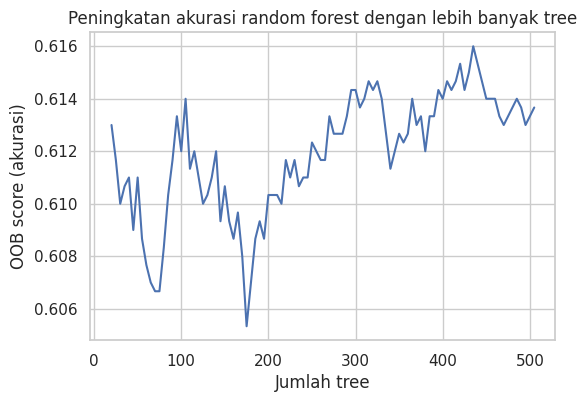

In [20]:
n_estimator = list(range(20, 510, 5))
oobScores = []
for n in n_estimator:
    rf_n = RandomForestClassifier(n_estimators=n, criterion='entropy',
                                  max_depth=5, random_state=1, oob_score=True,
                                  n_jobs=-1)
    rf_n.fit(X, y)
    oobScores.append(rf_n.oob_score_)

df_oob = pd.DataFrame({'n': n_estimator, 'oobScore': oobScores})
ax = df_oob.plot(x='n', y='oobScore', figsize=(6, 4), legend=False)
ax.set_xlabel('Jumlah tree')
ax.set_ylabel('OOB score (akurasi)')
ax.set_title('Peningkatan akurasi random forest dengan lebih banyak tree')
plt.show()

Pada buku, tingkat error turun cepat dari lebih dari 0,44 lalu
stabil di sekitar 0,385. Sekarang prediksi random forest dapat
diplot terhadap kedua predictor:

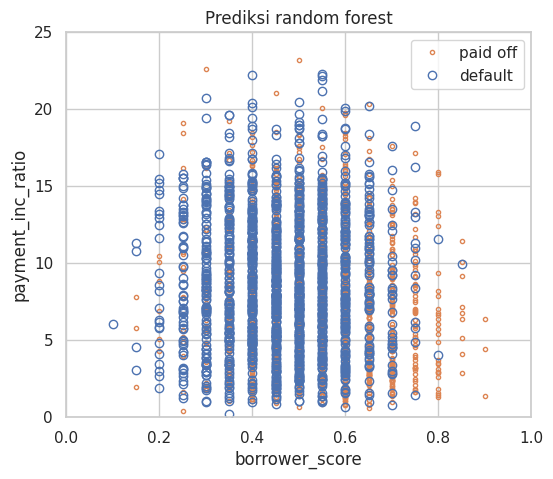

In [21]:
predictions = X.copy()
predictions['prediction'] = rf.predict(X)

fig, ax = plt.subplots(figsize=(6, 5))

predictions.loc[predictions.prediction == 'paid off'].plot(
    x='borrower_score', y='payment_inc_ratio', style='.',
    markerfacecolor='none', markeredgecolor='C1', ax=ax)
predictions.loc[predictions.prediction == 'default'].plot(
    x='borrower_score', y='payment_inc_ratio', style='o',
    markerfacecolor='none', markeredgecolor='C0', ax=ax)

ax.legend(['paid off', 'default'])
ax.set_xlim(0, 1)
ax.set_ylim(0, 25)
ax.set_xlabel('borrower_score')
ax.set_ylabel('payment_inc_ratio')
ax.set_title('Prediksi random forest')
plt.show()

Plot ini sangat menunjukkan sifat random forest. Random forest adalah
metode **kotak hitam**: menghasilkan prediksi lebih akurat daripada tree
tunggal sederhana, tetapi aturan keputusan intuitif tree tunggal
hilang. Prediksi random forest juga agak berisik: perhatikan bahwa
sebagian peminjam dengan skor sangat tinggi (kelayakan kredit tinggi)
tetap diprediksi *default*. Hal ini akibat beberapa record tidak biasa
pada data dan menunjukkan bahaya **overfitting** oleh random forest.

## Variable Importance

Kekuatan random forest terlihat ketika membangun model prediktif untuk
data dengan banyak fitur dan record. Algoritma ini dapat secara
otomatis menentukan predictor yang penting dan menemukan hubungan
kompleks antar predictor yang sesuai dengan *interaction terms*.
Berikut model dengan seluruh kolom disertakan:

In [22]:
predictors = ['loan_amnt', 'term', 'annual_inc', 'dti', 'payment_inc_ratio',
              'revol_bal', 'revol_util', 'purpose', 'delinq_2yrs_zero',
              'pub_rec_zero', 'open_acc', 'grade', 'emp_length', 'purpose_',
              'home_', 'emp_len_', 'borrower_score']
outcome = 'outcome'

X = pd.get_dummies(loan_data[predictors], drop_first=True, dtype=float)
y = loan_data[outcome]

rf_all = RandomForestClassifier(n_estimators=500, random_state=1, n_jobs=-1)
rf_all.fit(X, y)

print('Jumlah fitur setelah dummy encoding:', X.shape[1])

Jumlah fitur setelah dummy encoding: 33


`RandomForestClassifier` mengumpulkan informasi *feature importance*
saat pelatihan dan menyediakannya pada atribut
`feature_importances_` (ini adalah **mean decrease in Gini impurity**).
**Mean decrease in accuracy**, bagaimanapun, tidak tersedia secara
bawaan di Python, sehingga dihitung manual dengan mengacak
(*permute*) nilai satu variabel pada data validasi dan mengukur
penurunan akurasi.

In [23]:
rf = RandomForestClassifier(n_estimators=500, random_state=1, n_jobs=-1)
scores = defaultdict(list)

# Cross-validate skor pada beberapa pembagian acak data
for _ in range(3):
    train_X, valid_X, train_y, valid_y = train_test_split(X, y, test_size=0.3)
    rf.fit(train_X, train_y)
    acc = metrics.accuracy_score(valid_y, rf.predict(valid_X))
    for column in X.columns:
        X_t = valid_X.copy()
        X_t[column] = np.random.permutation(X_t[column].values)
        shuff_acc = metrics.accuracy_score(valid_y, rf.predict(X_t))
        scores[column].append((acc - shuff_acc) / acc)

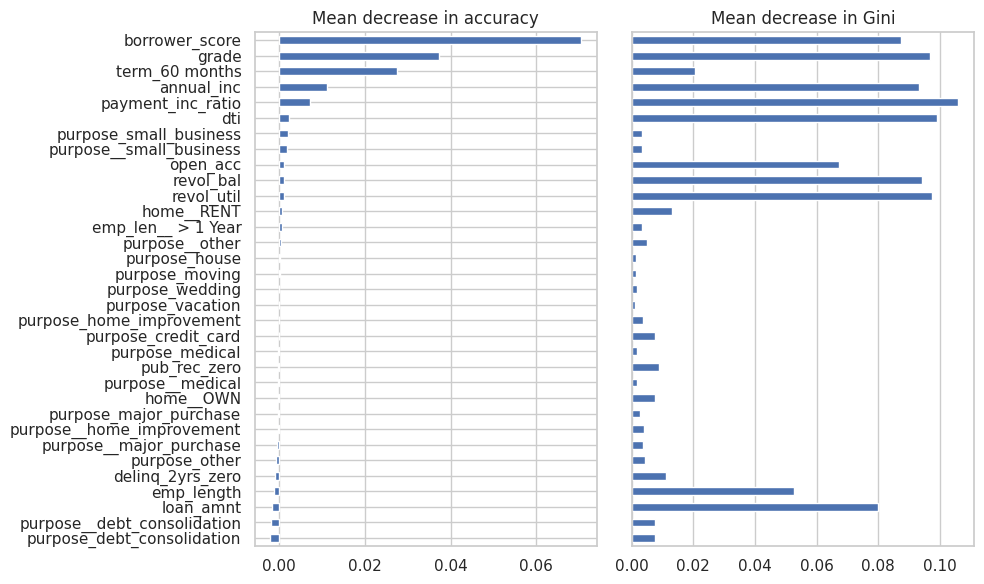

In [24]:
df_imp = pd.DataFrame({
    'feature': X.columns,
    'Accuracy decrease': [np.mean(scores[column]) for column in X.columns],
    'Gini decrease': rf_all.feature_importances_,
})
df_imp = df_imp.sort_values('Accuracy decrease')

fig, axes = plt.subplots(ncols=2, figsize=(10, 6))

ax = df_imp.plot(kind='barh', x='feature', y='Accuracy decrease',
                 legend=False, ax=axes[0])
ax.set_ylabel('')
ax.set_title('Mean decrease in accuracy')

ax = df_imp.plot(kind='barh', x='feature', y='Gini decrease',
                 legend=False, ax=axes[1])
ax.set_ylabel('')
ax.get_yaxis().set_visible(False)
ax.set_title('Mean decrease in Gini')

plt.tight_layout()
plt.show()

Ada dua cara mengukur **variable importance**:

- Berdasarkan **penurunan akurasi** model jika nilai variabel diacak
  (*permuted*). Mengacak nilai menghilangkan seluruh daya prediksi
  variabel itu. Pada R, akurasi dihitung dari data out-of-bag
  (sehingga efektif estimasi cross-validated).
- Berdasarkan **mean decrease in Gini impurity** untuk semua node yang
  di-split pada suatu variabel. Ini mengukur seberapa besar
  penyertaan variabel meningkatkan kemurnian node. Ukuran ini
  berdasar training set sehingga kurang andal.

Panel kiri dan kanan menunjukkan variable importance berdasarkan
penurunan akurasi dan penurunan Gini impurity. Skor kedua ukuran bisa
cukup berbeda.

Karena penurunan akurasi lebih andal, mengapa tetap memakai penurunan
Gini? Secara default Gini adalah *produk sampingan* algoritma,
sedangkan akurasi per variabel memerlukan komputasi tambahan
(mengacak data dan memprediksinya). Jika kompleksitas komputasi
penting (misal pada produksi yang melatih ribuan model), usaha ekstra
itu mungkin tidak sepadan. Selain itu, penurunan Gini menunjukkan
variabel mana yang dipakai random forest untuk aturan splitting
(informasi yang tampak jelas pada tree tunggal tetapi hilang di
random forest).

## Hyperparameters

Random forest, seperti banyak algoritma statistical machine learning,
dapat dipandang sebagai algoritma kotak hitam dengan "tombol" untuk
mengatur cara kerjanya. Tombol ini disebut **hyperparameters**, yaitu
parameter yang harus diatur **sebelum** model dicocokkan dan tidak
dioptimalkan sebagai bagian proses pelatihan. Dua hyperparameter paling
penting pada random forest:

- **`min_samples_leaf`** (nodesize di R) — ukuran minimum node
  terminal (leaf). Default 1 untuk klasifikasi dan 5 untuk regression
  di R. Implementasi scikit-learn memakai default 1 untuk keduanya.
- **`max_leaf_nodes`** (maxnodes di R) — jumlah maksimum node pada
  setiap decision tree. Secara default tidak ada batas, dan tree
  terbesar dicocokkan dengan kendala nodesize. Di Python yang
  ditentukan adalah jumlah maksimum node terminal. Kedua parameter
  berkaitan: $\text{maxnodes} = 2\times\text{max\_leaf\_nodes} - 1$.

Menggunakan nilai default bisa tergoda, tetapi dapat menyebabkan
**overfitting** pada data berisik. Dengan menaikkan
`min_samples_leaf` atau mengatur `max_leaf_nodes`, algoritma
mencocokkan tree yang lebih kecil dan lebih kecil kemungkinan membuat
aturan prediksi palsu. **Cross-validation** dapat dipakai menguji efek
berbagai nilai hyperparameter.

In [25]:
# Pengaruh min_samples_leaf terhadap OOB score (data loan3000, 2 predictor)
X2 = loan3000[['borrower_score', 'payment_inc_ratio']]
y2 = loan3000['outcome']

rows = []
for leaf in [1, 5, 10, 20, 50, 100]:
    rf_leaf = RandomForestClassifier(n_estimators=300, min_samples_leaf=leaf,
                                     random_state=1, oob_score=True, n_jobs=-1)
    rf_leaf.fit(X2, y2)
    rows.append({'min_samples_leaf': leaf, 'oob_score': rf_leaf.oob_score_})

pd.DataFrame(rows)

,min_samples_leaf,oob_score
0,1,0.573667
1,5,0.591333
2,10,0.595000
3,20,0.594000
4,50,0.606667
5,100,0.611667


### Key Ideas — Bagging and the Random Forest

- Model ensemble meningkatkan akurasi model dengan menggabungkan hasil
  banyak model.
- Bagging adalah jenis model ensemble yang mencocokkan banyak model ke
  sampel bootstrap dari data, lalu merata-ratakan model tersebut.
- Random forest adalah jenis khusus bagging pada decision tree. Selain
  me-resample data, algoritma random forest juga mengambil sampel
  variabel predictor saat men-split tree.
- Keluaran berguna dari random forest adalah ukuran variable
  importance yang meranking predictor berdasarkan kontribusinya pada
  akurasi model.
- Random forest memiliki hyperparameter yang harus di-tuning dengan
  cross-validation untuk menghindari overfitting.

# 4. Boosting

Model ensemble telah menjadi alat standar predictive modeling.
**Boosting** adalah teknik umum untuk membuat ensemble model, yang
dikembangkan hampir bersamaan dengan bagging. Seperti bagging,
boosting paling sering dipakai dengan decision tree. Meski mirip,
boosting memiliki pendekatan yang sangat berbeda dan dengan lebih
banyak "lonceng dan peluit" (opsi). Akibatnya, bagging dapat dilakukan
dengan relatif sedikit tuning, sedangkan boosting memerlukan kehati-
hatian lebih besar. Jika kedua metode adalah mobil, bagging ibarat
Honda Accord (andal dan stabil), sedangkan boosting ibarat Porsche
(bertenaga tetapi butuh perawatan).

Pada linear regression, residual sering diperiksa untuk melihat apakah
fit dapat ditingkatkan. Boosting membawa konsep ini jauh lebih
lanjut dan mencocokkan serangkaian model, di mana setiap model
berikutnya berupaya **meminimalkan error model sebelumnya**. Beberapa
varian algoritma umum dipakai: **Adaboost**, **gradient boosting**, dan
**stochastic gradient boosting**. Yang terakhir paling umum dan paling
banyak dipakai. Bahkan dengan pilihan parameter yang tepat, algoritma
ini dapat meniru random forest.

### Key Terms

- **Ensemble** — membentuk prediksi dengan kumpulan model.
- **Boosting** — teknik umum mencocokkan serangkaian model dengan
  memberi bobot lebih pada record dengan residual besar di tiap putaran
  berikutnya.
- **Adaboost** — versi boosting awal yang memberi bobot ulang pada
  data berdasarkan residual.
- **Gradient boosting** — bentuk boosting yang lebih umum, dirumuskan
  sebagai peminimalan fungsi biaya (cost function).
- **Stochastic gradient boosting** — algoritma boosting paling umum
  yang menyertakan resampling record dan kolom di tiap putaran.
- **Regularization** — teknik menghindari overfitting dengan
  menambahkan suku penalti pada cost function untuk jumlah parameter
  model.
- **Hyperparameters** — parameter yang harus diatur sebelum
  algoritma dijalankan.

## The Boosting Algorithm

Ada berbagai algoritma boosting, tetapi ide dasarnya pada dasarnya
sama. Yang paling mudah dipahami adalah **Adaboost**:

1. Inisialisasi M (jumlah maksimum model), dan penghitung iterasi
   m = 1. Inisialisasi bobot observasi $w_i = 1/N$ untuk
   $i = 1, \dots, N$. Inisialisasi model ensemble $\hat{F}_0 = 0$.
2. Dengan bobot observasi $w_1, \dots, w_N$, latih model $\hat{f}_m$
   yang meminimalkan **weighted error** $e_m$, yaitu jumlah bobot
   observasi yang salah diklasifikasikan.
3. Tambahkan model ke ensemble:
   $\hat{F}_m = \hat{F}_{m-1} + \alpha_m \hat{f}_m$ dengan
   $\alpha_m = \dfrac{\log\left(\frac{1-e_m}{e_m}\right)}{1}$.
4. Perbarui bobot sehingga bobot observasi yang salah
   diklasifikasikan **naik**. Besar kenaikan bergantung pada
   $\alpha_m$; nilai $\alpha_m$ lebih besar menghasilkan bobot lebih
   besar.
5. Naikkan m = m + 1. Jika m ≤ M, kembali ke langkah 2.

Estimasi boosted adalah:

$$
\hat{F} = \alpha_1 \hat{f}_1 + \alpha_2 \hat{f}_2 + \dots + \alpha_M \hat{f}_M
$$

Dengan menaikkan bobot observasi yang salah diklasifikasikan,
algoritma memaksa model berlatih lebih keras pada data yang performanya
buruk. Faktor $\alpha_m$ memastikan model dengan error lebih rendah
memiliki bobot lebih besar.

**Gradient boosting** mirip Adaboost, tetapi merumuskan masalah sebagai
optimasi cost function. Alih-alih menyesuaikan bobot, gradient
boosting mencocokkan model pada **pseudo-residual**, sehingga melatih
lebih berat pada residual yang lebih besar. Sejiwa dengan random
forest, **stochastic gradient boosting** menambahkan keacakan dengan
mengambil sampel observasi dan variabel predictor pada tiap tahap.

## XGBoost

Perangkat lunak domain publik paling banyak dipakai untuk boosting
adalah **XGBoost**, implementasi stochastic gradient boosting yang
awalnya dikembangkan oleh Tianqi Chen dan Carlos Guestrin di
University of Washington. Implementasinya efisien secara komputasi
dengan banyak opsi, dan tersedia sebagai package pada sebagian besar
perangkat lunak data science. XGBoost memiliki banyak parameter yang
dapat dan sebaiknya disesuaikan. Dua parameter yang sangat penting:

- **`subsample`** — mengontrol fraksi observasi yang diambil pada tiap
  iterasi. Dengan `subsample`, boosting bertindak seperti random forest
  kecuali pengambilan sampel dilakukan tanpa pengembalian.
- **`eta` (`learning_rate`)** — faktor penyusutan (*shrinkage*) yang
  diterapkan pada $\alpha_m$ pada algoritma boosting. Berguna mencegah
  overfitting dengan mengurangi perubahan bobot (perubahan bobot yang
  lebih kecil berarti algoritma lebih kecil kemungkinan overfit pada
  training set).

XGBoost di Python memiliki dua antarmuka: **scikit-learn API** dan
antarmuka yang lebih fungsional. Agar konsisten dengan metode
scikit-learn, sebagian parameter diganti namanya; misalnya `eta`
menjadi `learning_rate` (memakai `eta` tidak menimbulkan error tetapi
tidak memberi efek yang diinginkan).

Label kelas pada XGBoost harus numerik, sehingga outcome dikodekan
1 = *default* dan 0 = *paid off*.

In [26]:
predictors = ['borrower_score', 'payment_inc_ratio']

X = loan3000[predictors]
y = (loan3000['outcome'] == 'default').astype(int)   # 1 = default, 0 = paid off

xgb = XGBClassifier(objective='binary:logistic', subsample=0.63)
xgb.fit(X, y)

print(xgb)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)


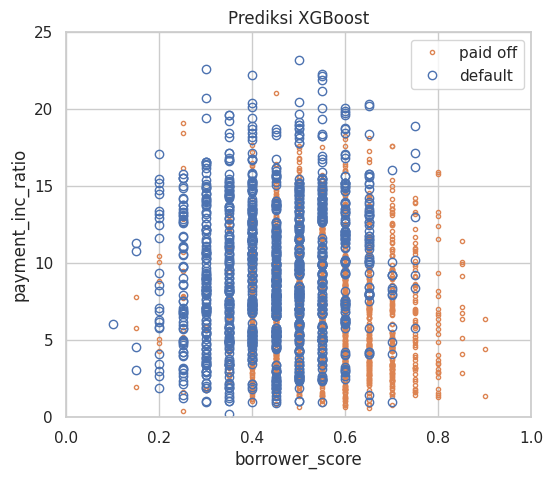

In [27]:
# Prediksi XGBoost dan visualisasinya terhadap kedua predictor
xgb_df = X.copy()
xgb_df['prediction'] = np.where(xgb.predict(X) == 1, 'default', 'paid off')

fig, ax = plt.subplots(figsize=(6, 5))

xgb_df.loc[xgb_df.prediction == 'paid off'].plot(
    x='borrower_score', y='payment_inc_ratio', style='.',
    markerfacecolor='none', markeredgecolor='C1', ax=ax)
xgb_df.loc[xgb_df.prediction == 'default'].plot(
    x='borrower_score', y='payment_inc_ratio', style='o',
    markerfacecolor='none', markeredgecolor='C0', ax=ax)

ax.legend(['paid off', 'default'])
ax.set_xlim(0, 1)
ax.set_ylim(0, 25)
ax.set_xlabel('borrower_score')
ax.set_ylabel('payment_inc_ratio')
ax.set_title('Prediksi XGBoost')
plt.show()

Secara kualitatif, hasilnya mirip prediksi random forest. Prediksinya
agak berisik: sebagian peminjam dengan skor sangat tinggi tetap
diprediksi *default*.

## Regularization: Avoiding Overfitting

Penerapan XGBoost secara membabi buta dapat menghasilkan model tidak
stabil akibat **overfitting** pada data latih. Masalah overfitting
ada dua:

- Akurasi model pada data baru di luar training set menurun.
- Prediksi model sangat bervariasi sehingga hasilnya tidak stabil.

Teknik pemodelan apa pun berpotensi overfit. Pada kebanyakan teknik
statistik, overfitting dapat dihindari dengan pemilihan variabel
predictor yang bijak. Bahkan random forest umumnya menghasilkan model
wajar tanpa tuning. Namun hal ini tidak berlaku untuk XGBoost.

Berikut XGBoost pada data pinjaman lengkap dengan semua variabel.
`train_test_split` memisahkan data menjadi training dan test set.

In [28]:
predictors = ['loan_amnt', 'term', 'annual_inc', 'dti', 'payment_inc_ratio',
              'revol_bal', 'revol_util', 'purpose', 'delinq_2yrs_zero',
              'pub_rec_zero', 'open_acc', 'grade', 'emp_length', 'purpose_',
              'home_', 'emp_len_', 'borrower_score']
outcome = 'outcome'

X = pd.get_dummies(loan_data[predictors], drop_first=True, dtype=float)
y = pd.Series([1 if o == 'default' else 0 for o in loan_data[outcome]])

train_X, valid_X, train_y, valid_y = train_test_split(X, y, test_size=10000,
                                                      random_state=1)

xgb_default = XGBClassifier(objective='binary:logistic', n_estimators=250,
                            max_depth=6, reg_lambda=0, learning_rate=0.3,
                            subsample=1)
xgb_default.fit(train_X, train_y)

pred_default = xgb_default.predict_proba(valid_X)[:, 1]
error_default = abs(valid_y - pred_default) > 0.5
print('default (test error): ', np.mean(error_default))

default (test error):  0.359


Test set berisi 10.000 record yang diambil acak dari seluruh data, dan
training set berisi sisanya. Pada buku, boosting menghasilkan tingkat
error hanya 13,3% pada training set, tetapi **35,3% pada test set**.
Ini akibat **overfitting**: boosting menjelaskan variabilitas pada
training set dengan sangat baik, tetapi aturan prediksinya tidak
berlaku pada data baru.

Boosting menyediakan beberapa parameter untuk menghindari overfitting,
termasuk `eta` (`learning_rate`) dan `subsample`. Pendekatan lain adalah
**regularization**, teknik yang memodifikasi cost function untuk
**menghukum kompleksitas model**. Decision tree dicocokkan dengan
meminimalkan kriteria biaya seperti Gini impurity. Pada XGBoost,
cost function dapat dimodifikasi dengan menambahkan suku yang
mengukur kompleksitas model.

Ada dua parameter regularisasi pada XGBoost: **alpha** dan **lambda**,
yang masing-masing sesuai dengan Manhattan distance (regularisasi L1)
dan squared Euclidean distance (regularisasi L2). Menaikkan parameter
ini akan menghukum model yang lebih kompleks dan memperkecil ukuran
tree yang dicocokkan. Pada scikit-learn API, parameternya disebut
`reg_alpha` dan `reg_lambda`. Berikut efeknya jika `reg_lambda` diatur
1.000:

In [29]:
xgb_penalty = XGBClassifier(objective='binary:logistic', n_estimators=250,
                            max_depth=6, reg_lambda=1000, learning_rate=0.1,
                            subsample=0.63)
xgb_penalty.fit(train_X, train_y)

pred_penalty = xgb_penalty.predict_proba(valid_X)[:, 1]
error_penalty = abs(valid_y - pred_penalty) > 0.5
print('penalty (test error): ', np.mean(error_penalty))

penalty (test error):  0.3313


Kini error pada training set hanya sedikit lebih rendah daripada error
pada test set.

Untuk membandingkan error in-sample dan out-of-sample ketika jumlah
tree bertambah, prediksi dihitung hanya dengan memakai **i tree
pertama**. Pada XGBoost versi terbaru ini dilakukan dengan argumen
`iteration_range` (menggantikan `ntree_limit` yang dipakai pada buku
dan sudah tidak didukung pada versi baru).

In [30]:
results = []
for i in range(1, 250):
    rng = (0, i)
    train_default = xgb_default.predict_proba(train_X, iteration_range=rng)[:, 1]
    train_penalty = xgb_penalty.predict_proba(train_X, iteration_range=rng)[:, 1]
    pred_default = xgb_default.predict_proba(valid_X, iteration_range=rng)[:, 1]
    pred_penalty = xgb_penalty.predict_proba(valid_X, iteration_range=rng)[:, 1]
    results.append({
        'iterations': i,
        'default train': np.mean(abs(train_y - train_default) > 0.5),
        'penalty train': np.mean(abs(train_y - train_penalty) > 0.5),
        'default test': np.mean(abs(valid_y - pred_default) > 0.5),
        'penalty test': np.mean(abs(valid_y - pred_penalty) > 0.5),
    })

results = pd.DataFrame(results)
results.head()

,iterations,default train,penalty train,default test,penalty test
0,1,0.342058,0.354338,0.3486,0.3550
1,2,0.331843,0.345425,0.3383,0.3439
2,3,0.327995,0.340643,0.3370,0.3443
3,4,0.324203,0.342001,0.3347,0.3418
4,5,0.322251,0.336710,0.3337,0.3391


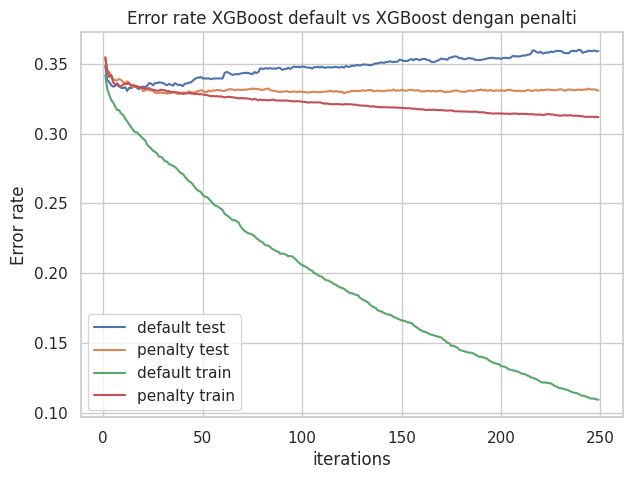

In [31]:
ax = results.plot(x='iterations', y='default test', figsize=(7, 5))
results.plot(x='iterations', y='penalty test', ax=ax)
results.plot(x='iterations', y='default train', ax=ax)
results.plot(x='iterations', y='penalty train', ax=ax)
ax.set_ylabel('Error rate')
ax.set_title('Error rate XGBoost default vs XGBoost dengan penalti')
plt.show()

Grafik menunjukkan model default terus meningkatkan akurasi pada
training set tetapi justru **memburuk pada test set**. Model dengan
penalti tidak menunjukkan perilaku ini.

> **Ridge Regression and the Lasso.** Menambahkan penalti pada
> kompleksitas model untuk membantu menghindari overfitting sudah ada
> sejak 1970-an. Least squares regression meminimalkan residual sum of
> squares (RSS). **Ridge regression** meminimalkan jumlah kuadrat
> residual ditambah suku penalti yang merupakan fungsi jumlah dan
> besar koefisien:
>
> $\sum_{i=1}^{n}(Y_i - b_0 - b_1X_i - \dots - b_pX_p)^2 + \lambda(b_1^2 + \dots + b_p^2)$
>
> Nilai $\lambda$ menentukan seberapa besar koefisien dihukum; nilai
> lebih besar menghasilkan model yang lebih kecil kemungkinan
> overfit. **Lasso** serupa, tetapi memakai Manhattan distance sebagai
> suku penalti:
>
> $\sum_{i=1}^{n}(Y_i - b_0 - b_1X_i - \dots - b_pX_p)^2 + \alpha(|b_1| + \dots + |b_p|)$
>
> Parameter xgboost `lambda` (`reg_lambda`) dan `alpha` (`reg_alpha`)
> bekerja dengan cara serupa. Euclidean distance disebut juga
> regularisasi L2 dan Manhattan distance regularisasi L1.

## Hyperparameters and Cross-Validation

XGBoost memiliki banyak hyperparameter. Pilihan spesifik dapat
mengubah hasil fit secara dramatis. Dengan banyaknya kombinasi
hyperparameter, solusi standar adalah **cross-validation**.
Cross-validation membagi data secara acak menjadi K kelompok (*folds*).
Untuk tiap fold, model dilatih pada data di luar fold, lalu dievaluasi
pada data di dalam fold. Hasilnya adalah ukuran akurasi model pada data
out-of-sample. Set hyperparameter terbaik adalah yang memberi model
dengan error keseluruhan terendah (rata-rata error tiap fold).

Sebagai ilustrasi, dieksplorasi dua parameter: shrinkage `eta`
(`learning_rate`) dan kedalaman maksimum tree `max_depth` (jarak
terjauh dari leaf ke root; default 6 pada R dan 3 pada scikit-learn
API). `max_depth` memberi cara lain mengontrol overfitting: tree dalam
cenderung lebih kompleks dan mungkin overfit.

Berikut semua kombinasi hyperparameter dibuat dengan
`itertools.product`, lalu model dicocokkan dan dievaluasi dengan 5
fold untuk setiap kombinasi. Karena ada 45 model yang dicocokkan, proses
ini dapat memakan waktu beberapa menit.

In [32]:
idx = np.random.choice(range(5), size=len(X), replace=True)
error = []

for eta, max_depth in product([0.1, 0.5, 0.9], [3, 6, 9]):
    xgb = XGBClassifier(objective='binary:logistic', n_estimators=250,
                        max_depth=max_depth, learning_rate=eta)
    cv_error = []
    for k in range(5):
        fold_idx = idx == k
        train_X = X.loc[~fold_idx]; train_y = y[~fold_idx]
        valid_X = X.loc[fold_idx]; valid_y = y[fold_idx]

        xgb.fit(train_X, train_y)
        pred = xgb.predict_proba(valid_X)[:, 1]
        cv_error.append(np.mean(abs(valid_y - pred) > 0.5))
    error.append({
        'eta': eta,
        'max_depth': max_depth,
        'avg_error': np.mean(cv_error)
    })
    print(error[-1])

errors = pd.DataFrame(error)
errors

{'eta': 0.1, 'max_depth': 3, 'avg_error': np.float64(0.32858889720259166)}
{'eta': 0.1, 'max_depth': 6, 'avg_error': np.float64(0.3375142808326719)}
{'eta': 0.1, 'max_depth': 9, 'avg_error': np.float64(0.3484476467874445)}
{'eta': 0.5, 'max_depth': 3, 'avg_error': np.float64(0.3414713456185708)}
{'eta': 0.5, 'max_depth': 6, 'avg_error': np.float64(0.3719036878635218)}
{'eta': 0.5, 'max_depth': 9, 'avg_error': np.float64(0.3690023409752553)}
{'eta': 0.9, 'max_depth': 3, 'avg_error': np.float64(0.3529528747948191)}
{'eta': 0.9, 'max_depth': 6, 'avg_error': np.float64(0.3872795979758973)}
{'eta': 0.9, 'max_depth': 9, 'avg_error': np.float64(0.38139386924493207)}


,eta,max_depth,avg_error
0,0.1,3,0.328589
1,0.1,6,0.337514
2,0.1,9,0.348448
3,0.5,3,0.341471
4,0.5,6,0.371904
5,0.5,9,0.369002
6,0.9,3,0.352953
7,0.9,6,0.387280
8,0.9,9,0.381394


Hasil cross-validation pada buku menunjukkan bahwa tree yang lebih
dangkal dengan `eta`/`learning_rate` yang lebih kecil menghasilkan
hasil lebih akurat. Karena model seperti ini juga lebih stabil,
parameter terbaik adalah `eta = 0,1` dan `max_depth = 3` (atau mungkin
`max_depth = 6`).

Berikut ringkasan dalam bentuk tabel pivot:

In [33]:
errors.pivot(index='eta', columns='max_depth', values='avg_error').round(4)

max_depth,3,6,9
eta,,,
0.1,0.3286,0.3375,0.3484
0.5,0.3415,0.3719,0.3690
0.9,0.3530,0.3873,0.3814


### XGBoost Hyperparameters

Hyperparameter XGBoost terutama dipakai untuk menyeimbangkan
overfitting dengan akurasi dan kompleksitas komputasi.

| Hyperparameter | Keterangan |
|---|---|
| `eta` / `learning_rate` | Faktor shrinkage antara 0 dan 1 yang diterapkan pada α di algoritma boosting. Default 0,3 (R), tetapi untuk data berisik disarankan nilai lebih kecil (misal 0,1). Di Python default 0,1. |
| `nrounds` / `n_estimators` | Jumlah putaran boosting. Jika `eta` kecil, jumlah putaran harus dinaikkan karena algoritma belajar lebih lambat. Selama ada parameter pencegah overfitting, lebih banyak putaran tidak merugikan. |
| `max_depth` | Kedalaman maksimum tree (default 6). Berbeda dengan random forest yang memakai tree sangat dalam, boosting biasanya memakai tree dangkal untuk menghindari interaksi kompleks palsu dari data berisik. Di Python default 3. |
| `subsample` dan `colsample_bytree` | Fraksi record yang diambil tanpa pengembalian dan fraksi predictor yang diambil untuk membangun tree. Mirip random forest, membantu menghindari overfitting. Default 1,0. |
| `lambda` / `reg_lambda` dan `alpha` / `reg_alpha` | Parameter regularisasi untuk membantu mengontrol overfitting. Default Python `reg_lambda=1` dan `reg_alpha=0`. Pada R, keduanya default 0. |

### Key Ideas — Boosting

- Boosting adalah kelas model ensemble berdasarkan pencocokan serangkaian
  model, dengan bobot lebih besar diberikan pada record dengan error
  besar pada putaran berikutnya.
- Stochastic gradient boosting adalah jenis boosting paling umum dan
  menawarkan performa terbaik. Bentuk paling umum memakai model tree.
- XGBoost adalah package populer dan efisien secara komputasi untuk
  stochastic gradient boosting, tersedia di semua bahasa umum data
  science.
- Boosting rentan overfitting dan hyperparameter harus di-tuning untuk
  menghindarinya.
- Regularization adalah salah satu cara menghindari overfitting dengan
  menyertakan suku penalti pada jumlah parameter (misalnya ukuran tree)
  pada model.
- Cross-validation sangat penting untuk boosting karena banyaknya
  hyperparameter yang harus ditetapkan.

# Key Ideas — Chapter 6

### 1. Statistical Machine Learning
Metode supervised learning yang data-driven dan tidak memaksakan
struktur linear pada data, misalnya KNN, tree, dan ensemble tree.

### 2. K-Nearest Neighbors
Mengklasifikasikan record berdasarkan kelas mayoritas K tetangga
terdekat. Variabel perlu distandardisasi, dan K dipilih dengan data
validasi.

### 3. Tree Models
Rangkaian aturan if-then-else hasil recursive partitioning dengan
ukuran impurity (Gini atau entropy). Tree penuh overfit sehingga
kompleksitasnya harus dikontrol.

### 4. Bagging dan Random Forest
Ensemble tree dari bootstrap sample ditambah pengambilan sampel
variabel pada tiap split. Menyediakan variable importance dan OOB
error.

### 5. Boosting
Ensemble berurutan di mana tiap model memperbaiki error model
sebelumnya. XGBoost adalah implementasi populer yang sangat bergantung
pada regularization dan tuning hyperparameter.

### 6. Bias-Variance Trade-off dan Cross-Validation
Model yang terlalu fleksibel overfit (variance tinggi), model yang
terlalu sederhana bias tinggi. Cross-validation membantu memilih
kompleksitas yang tepat.

## Kesimpulan

Chapter 6 membahas dua metode klasifikasi dan prediksi yang belajar
secara fleksibel dan lokal dari data, bukan memulai dengan model
struktural (misalnya linear regression) yang dicocokkan pada seluruh
data.

**K-Nearest Neighbors** adalah proses sederhana yang melihat record
serupa di sekitarnya dan memberi kelas mayoritas (atau nilai rata-rata)
pada record yang diprediksi. **Tree models** mencoba berbagai nilai
cutoff (split) pada variabel predictor dan secara iteratif membagi data
menjadi bagian dan sub-bagian yang makin homogen terhadap kelas. Nilai
split paling efektif membentuk jalur, sekaligus "aturan", untuk
klasifikasi atau prediksi.

Tree model adalah alat prediktif yang sangat kuat dan populer, sering
mengungguli metode lain. Dari tree lahir berbagai metode ensemble
(**random forest, boosting, bagging**) yang mempertajam daya prediksi
tree. Random forest cukup kokoh dengan sedikit tuning, sedangkan
boosting (XGBoost) sangat kuat tetapi memerlukan regularization dan
cross-validation yang cermat agar tidak overfit.